In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from pathlib import Path

def create_sankey(data, weight_column, title, save_path=None, top_n_links=100):
    top_paths = data.sort_values(weight_column, ascending=False).head(top_n_links).reset_index(drop=True)
    
    token_nodes = [f"Pos {pos}" for pos in top_paths['token_idx'].unique()]
    feature_nodes = [f"Feat {f_idx}" for f_idx in top_paths['feature_idx'].unique()]
    all_nodes = token_nodes + feature_nodes
    
    node_map = {name: i for i, name in enumerate(all_nodes)}
    
    sources = top_paths['token_idx'].apply(lambda x: node_map[f"Pos {x}"]).tolist()
    targets = top_paths['feature_idx'].apply(lambda x: node_map[f"Feat {x}"]).tolist()
    values = top_paths[weight_column].tolist()
    
    fig = go.Figure(data=[go.Sankey(
        node = dict(
          pad = 15,
          thickness = 20,
          line = dict(color = "black", width = 0.5),
          label = all_nodes,
          color = "#333333"
        ),
        link = dict(
          source = sources,
          target = targets,
          value = values,
          color = "rgba(100, 149, 237, 0.4)",
          hovertemplate='Source: %{source.label}<br>Target: %{target.label}<br>Weight: %{value}<extra></extra>'
        )
    )])
    
    fig.update_layout(title_text=title, font_size=12, height=800)
    
    if save_path:
        fig.write_html(save_path)
    else:
        fig.show()

def create_heatmap(data, weight_column, title, save_path=None, top_n_features=100):
    top_features = data.groupby('feature_idx')[weight_column].sum().sort_values(ascending=False).head(top_n_features).index
    filtered_data = data[data['feature_idx'].isin(top_features)]
    
    matrix = filtered_data.pivot(index='feature_idx', columns='token_idx', values=weight_column).fillna(0)
    
    matrix['total_weight'] = matrix.sum(axis=1)
    matrix = matrix.sort_values('total_weight', ascending=True).drop(columns=['total_weight'])
    
    z_raw = matrix.values
    z_log = np.log1p(z_raw)
    
    y_labels = [f"Feat {int(f)}" for f in matrix.index]
    x_labels = [f"Pos {int(p)}" for p in matrix.columns]
    
    fig = go.Figure(data=go.Heatmap(
        z=z_log, 
        x=x_labels,
        y=y_labels,
        customdata=z_raw, 
        colorscale='Viridis',
        hovertemplate='Position: %{x}<br>Feature: %{y}<br>Raw Value: %{customdata:,.2f}<extra></extra>'
    ))
    
    fig.update_layout(
        title_text=title,
        xaxis_title="Token Position",
        yaxis_title=f"Top {top_n_features} Features",
        height=700,
        yaxis=dict(type='category', dtick=1) 
    )
    
    if save_path:
        fig.write_html(save_path)
    else:
        fig.show()

def analyze_layer(layer_df, top_k=100, save_dir=None, spatial_weights=['count', 'sum', 'max_to_mean']):
    if save_dir and not os.path.exists(save_dir):
        os.makedirs(save_dir)

    def finish_plot(filename):
        if save_dir:
            plt.savefig(os.path.join(save_dir, filename), dpi=150)
            plt.close()
        else:
            plt.show()

    print(f"Number of unique features: {layer_df['feature_idx'].nunique()}")
    layer_counts = layer_df["feature_idx"].value_counts()

    plt.figure(figsize=(10, 5))
    plt.plot(np.arange(1, len(layer_counts) + 1), layer_counts.values)
    plt.yscale('log')
    plt.title("Feature Firing Count by Rank")
    plt.xlabel("Feature Rank")
    plt.ylabel("Firing Count")
    plt.grid(True, ls="--", alpha=0.5)
    finish_plot("rank_vs_frequency.png")

    plt.figure(figsize=(10, 5))
    plt.hist(np.log10(layer_counts.values), bins=50, edgecolor='black', alpha=0.7)
    plt.title("Distribution of Feature Firing Frequencies")
    plt.xlabel("Log10(Firing Count)")
    plt.ylabel("Number of Features")
    finish_plot("log_counts_histogram.png")

    layer_avg_feature_activation = layer_df.groupby("feature_idx")["activation"].mean()
    plt.figure(figsize=(10, 5))
    plt.hist(np.log10(layer_avg_feature_activation.values), bins=50, edgecolor='black', alpha=0.7)
    plt.title("Distribution of Mean Feature Activations")
    plt.xlabel("Log10(Mean Activation)")
    plt.ylabel("Number of Features")
    finish_plot("log_activation_histogram.png")

    layer_top_features = layer_counts.nlargest(top_k).index
    layer_df_top = layer_df[layer_df['feature_idx'].isin(layer_top_features)]
    
    fig, ax = plt.subplots(figsize=(14, 10))
    sns.boxplot(
        data=layer_df_top, 
        x='feature_idx', 
        y='activation', 
        order=layer_top_features, 
        color='lightgray',
        showfliers=False,
        ax=ax
    )
    sns.stripplot(
        data=layer_df_top, 
        x='feature_idx', 
        y='activation', 
        order=layer_top_features, 
        alpha=0.4, 
        size=3,
        jitter=True,
        ax=ax
    )
    ax.set_title(f"Activation Density (Top {top_k} Features) Ordered by Count")
    ax.set_xlabel("Feature Index")
    ax.set_ylabel("Activation Magnitude")
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    finish_plot("activation_density_boxplots.png")

    layer_feat_stats = layer_df.groupby('feature_idx')['activation'].agg(['max', 'mean', 'count']).reset_index()
    layer_feat_stats['max_to_mean_ratio'] = layer_feat_stats['max'] / layer_feat_stats['mean']
    
    fig, ax = plt.subplots(figsize=(10, 7))
    sc = ax.scatter(
        np.log10(layer_feat_stats['count']), 
        layer_feat_stats['mean'], 
        c=np.log10(layer_feat_stats['max_to_mean_ratio'] + 1e-9),
        cmap='plasma', 
        alpha=0.6, 
        s=15
    )
    ax.set_title("SAE Feature Landscape: Frequency vs. Magnitude")
    ax.set_xlabel("Log10(Firing Count)")
    ax.set_ylabel("Mean Activation Magnitude")
    cb = fig.colorbar(sc, ax=ax)
    cb.set_label("Log10(Max Over Mean Activation)")
    ax.grid(True, ls="--", alpha=0.4)
    plt.tight_layout()
    finish_plot("frequency_vs_magnitude_landscape.png")

    agg_df = layer_df.groupby(['token_idx', 'feature_idx'])['activation'].agg(['count', 'sum', 'max', 'mean']).reset_index()
    
    # Calculate the max-to-mean token burstiness metric (avoids div zero if any logic changes)
    agg_df['max_to_mean'] = np.where(agg_df['mean'] > 0, agg_df['max'] / agg_df['mean'], 0)

    for w_col in spatial_weights:
        sankey_title = f"SAE Feature Activation Flow (Weighted by {w_col} - Top {top_k})"
        heatmap_title = f"SAE Feature Density (Weighted by {w_col} - Top {top_k})"
        
        sankey_file = os.path.join(save_dir, f"sankey_{w_col}.html") if save_dir else None
        heatmap_file = os.path.join(save_dir, f"heatmap_{w_col}.html") if save_dir else None
        
        create_sankey(agg_df, weight_column=w_col, title=sankey_title, save_path=sankey_file, top_n_links=top_k)
        create_heatmap(agg_df, weight_column=w_col, title=heatmap_title, save_path=heatmap_file, top_n_features=top_k)

In [2]:
import plotly.express as px

def standardize_to_rgba(color_str, alpha=0.4):
    if color_str.startswith('rgb'):
        vals = color_str.replace('rgba', '').replace('rgb', '').replace('(', '').replace(')', '')
        r, g, b = [v.strip() for v in vals.split(',')][:3]
        return f"rgba({r}, {g}, {b}, {alpha})"
    
    hex_color = color_str.lstrip('#')
    r, g, b = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
    return f"rgba({r}, {g}, {b}, {alpha})"

def create_multilayer_sankey(df, weight_column, title="Multi-Layer Feature Flow", save_path=None, top_k_per_layer=50):
    # Failsafe: Flatten the dataframe if 'layer' is trapped in a MultiIndex
    if 'layer' not in df.columns and 'layer' in df.index.names:
        df = df.reset_index()
        
    # Robust vectorized sampling (avoids the apply/nlargest index destruction bug)
    top_paths = df.sort_values(weight_column, ascending=False)\
                  .groupby('layer', as_index=False)\
                  .head(top_k_per_layer)\
                  .reset_index(drop=True)
    
    sorted_tokens = sorted(top_paths['token_idx'].unique())
    
    top_paths['node_name'] = top_paths.apply(lambda r: f"L{int(r['layer'])}_F{int(r['feature_idx'])}", axis=1)
    
    sorted_features = top_paths.sort_values(['layer', 'feature_idx'])['node_name'].unique().tolist()
    
    token_nodes = [f"Pos {pos}" for pos in sorted_tokens]
    all_nodes = token_nodes + sorted_features
    node_map = {name: i for i, name in enumerate(all_nodes)}
    
    node_x = []
    node_y = []
    
    for i in range(len(token_nodes)):
        node_x.append(0.01)
        node_y.append(i / (len(token_nodes) - 1) if len(token_nodes) > 1 else 0.5)
        
    for i in range(len(sorted_features)):
        node_x.append(0.99)
        node_y.append(i / (len(sorted_features) - 1) if len(sorted_features) > 1 else 0.5)
        
    sources = top_paths['token_idx'].apply(lambda x: node_map[f"Pos {x}"]).tolist()
    targets = top_paths['node_name'].apply(lambda x: node_map[x]).tolist()
    values = top_paths[weight_column].tolist()
    
    unique_layers = sorted(top_paths['layer'].unique())
    palette = px.colors.qualitative.Plotly + px.colors.qualitative.Set1 
    layer_colors = {l: standardize_to_rgba(palette[i % len(palette)], 0.4) for i, l in enumerate(unique_layers)}
    link_colors = top_paths['layer'].map(layer_colors).tolist()
    
    fig = go.Figure(data=[go.Sankey(
        arrangement="snap",
        node = dict(
          pad = 15,
          thickness = 20,
          line = dict(color = "black", width = 0.5),
          label = all_nodes,
          color = "#333333",
          x = node_x,
          y = node_y
        ),
        link = dict(
          source = sources,
          target = targets,
          value = values,
          color = link_colors,
          customdata = top_paths['layer'].tolist(),
          hovertemplate='Layer: %{customdata}<br>Source: %{source.label}<br>Target: %{target.label}<br>Weight: %{value}<extra></extra>'
        )
    )])
    
    dynamic_height = max(800, len(sorted_features) * 15)
    
    fig.update_layout(title_text=title, font_size=12, height=dynamic_height)
    
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.write_html(save_path)
    else:
        fig.show()

In [3]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from collections import defaultdict
from tqdm.notebook import tqdm

def standardize_to_rgba(color_str, alpha=0.3):
    if color_str.startswith('rgb'):
        vals = color_str.replace('rgba', '').replace('rgb', '').replace('(', '').replace(')', '')
        r, g, b = [v.strip() for v in vals.split(',')][:3]
        return f"rgba({r}, {g}, {b}, {alpha})"
    
    hex_color = color_str.lstrip('#')
    r, g, b = tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))
    return f"rgba({r}, {g}, {b}, {alpha})"

def create_sequential_cofiring_sankey(df, weight_col='sum', top_k_links=30, save_path=None):
    # 1. Identify valid layers
    layers = sorted(df['layer'].unique())
    if len(layers) < 2:
        print("Error: Dataset must contain at least 2 layers to map transitions.")
        return

    all_links = []

    print("Mapping causal transitions...")
    # 2. Extract top co-activations layer-by-layer
    for i in tqdm(range(len(layers) - 1)):
        src_l = layers[i]
        tgt_l = layers[i+1]

        src_df = df[df['layer'] == src_l][['prompt_idx', 'token_idx', 'feature_idx', 'activation']]
        tgt_df = df[df['layer'] == tgt_l][['prompt_idx', 'token_idx', 'feature_idx', 'activation']]

        src_df = src_df.rename(columns={'feature_idx': 'src_f', 'activation': 'src_a'})
        tgt_df = tgt_df.rename(columns={'feature_idx': 'tgt_f', 'activation': 'tgt_a'})

        merged = pd.merge(src_df, tgt_df, on=['prompt_idx', 'token_idx'])
        
        if merged.empty:
            continue

        merged['joint_mass'] = merged['src_a'] * merged['tgt_a']

        if weight_col == 'count':
            agg = merged.groupby(['src_f', 'tgt_f']).size().reset_index(name='weight')
        else:
            agg = merged.groupby(['src_f', 'tgt_f'])['joint_mass'].sum().reset_index(name='weight')

        top_agg = agg.nlargest(top_k_links, 'weight').copy()
        top_agg['src_layer'] = src_l
        top_agg['tgt_layer'] = tgt_l
        
        all_links.append(top_agg)

    if not all_links:
        print("No co-firing links found across the given layers.")
        return

    flow_df = pd.concat(all_links, ignore_index=True)

    # 3. Create global node namespace
    flow_df['src_name'] = flow_df.apply(lambda r: f"L{int(r['src_layer'])}_F{int(r['src_f'])}", axis=1)
    flow_df['tgt_name'] = flow_df.apply(lambda r: f"L{int(r['tgt_layer'])}_F{int(r['tgt_f'])}", axis=1)

    unique_nodes = list(pd.concat([flow_df['src_name'], flow_df['tgt_name']]).unique())
    node_map = {n: i for i, n in enumerate(unique_nodes)}

    # 4. Strict Geometric Positioning
    layer_to_nodes = defaultdict(list)
    for node in unique_nodes:
        # Extract layer integer from string (e.g., "L2_F104" -> 2)
        l_val = int(node.split('_')[0][1:])
        layer_to_nodes[l_val].append(node)

    l_indices = {l: i for i, l in enumerate(layers)}
    max_l_idx = len(layers) - 1

    node_coords = {}
    for l_val, nodes_in_l in layer_to_nodes.items():
        # Sort nodes numerically by feature ID
        nodes_in_l.sort(key=lambda x: int(x.split('_')[1][1:]))
        
        # Calculate X coordinate (evenly spaced columns)
        x_val = 0.01 + (l_indices[l_val] / max_l_idx) * 0.98 if max_l_idx > 0 else 0.5
        
        # Calculate Y coordinate (evenly spaced rows)
        for idx, node in enumerate(nodes_in_l):
            y_val = idx / (len(nodes_in_l) - 1) if len(nodes_in_l) > 1 else 0.5
            node_coords[node] = (x_val, y_val)

    node_x = [node_coords[n][0] for n in unique_nodes]
    node_y = [node_coords[n][1] for n in unique_nodes]

    # 5. Map to Plotly indices
    sources = flow_df['src_name'].apply(lambda x: node_map[x]).tolist()
    targets = flow_df['tgt_name'].apply(lambda x: node_map[x]).tolist()
    values = flow_df['weight'].tolist()

    # 6. Apply Layer-Specific Colors
    palette = px.colors.qualitative.Plotly + px.colors.qualitative.Set1 
    layer_colors = {l: standardize_to_rgba(palette[i % len(palette)], 0.35) for i, l in enumerate(layers)}
    link_colors = flow_df['src_layer'].map(layer_colors).tolist()

    print("Rendering visualization...")
    fig = go.Figure(data=[go.Sankey(
        arrangement="snap",
        node = dict(
          pad = 12,
          thickness = 15,
          line = dict(color = "black", width = 0.5),
          label = unique_nodes,
          color = "#333333",
          x = node_x,
          y = node_y
        ),
        link = dict(
          source = sources,
          target = targets,
          value = values,
          color = link_colors,
          customdata = flow_df['src_layer'].tolist(),
          hovertemplate='Source: %{source.label}<br>Target: %{target.label}<br>Co-Activation Weight: %{value:,.2f}<extra></extra>'
        )
    )])
    
    dynamic_height = max(800, len(unique_nodes) * 8)
    fig.update_layout(
        title_text=f"Sequential Feature Co-Activation Flow (Top {top_k_links} edges per layer pair)", 
        font_size=11, 
        height=dynamic_height
    )
    
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.write_html(save_path)
    else:
        fig.show()

In [10]:
def compute_sae_metrics(df, value_col="activation"):
    df["abs_val"] = df[value_col].abs()

    total_layer_mass = df.groupby("layer")["abs_val"].transform("sum")
    total_feature_mass = df.groupby(["layer", "feature_idx"])["abs_val"].transform("sum")
    total_pos_mass = df.groupby(["layer", "token_idx"])["abs_val"].transform("sum")
    total_token_mass = df.groupby(["layer", "token_id"])["abs_val"].transform("sum")

    feat_pos_mass = df.groupby(["layer", "feature_idx", "token_idx"])["abs_val"].transform("sum")
    feat_token_mass = df.groupby(["layer", "feature_idx", "token_id"])["abs_val"].transform("sum")

    eps = 1e-9
    df["position_mass"] = feat_pos_mass / (total_pos_mass + eps)
    df["position_specificity"] = feat_pos_mass / (total_feature_mass + eps)
    df["token_mass"] = feat_token_mass / (total_token_mass + eps)
    df["token_specificity"] = feat_token_mass / (total_feature_mass + eps)
    df["inverse_layer_mass"] = np.log10((total_layer_mass + eps) / (total_feature_mass + eps))

    df.drop(columns=["abs_val"], inplace=True)
    return df

In [42]:
import plotly.express as px

def plot_parallel_feature_profiles(df, layer_idx):
    layer_df = df[df['layer'] == layer_idx].copy()
    
    layer_df = layer_df.groupby('feature_idx')[
        ['token_mass', 'token_specificity', 'inverse_layer_mass'] # 'position_mass', 'position_specificity', 
    ].mean().reset_index()

    fig = px.parallel_coordinates(
        layer_df,
        dimensions=['token_mass', 'token_specificity', 'inverse_layer_mass'],
        color='inverse_layer_mass',
        color_continuous_scale=px.colors.diverging.Tealrose,
        title=f"Feature Metric Profiles (Layer {layer_idx})"
    )
    
    fig.update_layout(height=600)
    fig.show()

In [4]:
import pyarrow.dataset as ds

dataset = ds.dataset('../sae_activations/', format='parquet', partitioning='hive')
full_df = dataset.to_table().to_pandas()

In [8]:
full_df

/lv_local/home/maximilian.m/anaconda3/envs/sae/lib/python3.11/site-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,prompt_idx,token_idx,token_id,feature_idx,activation,layer
0,6150,0,50256,663,1.609375,0
1,6150,0,50256,14525,1.477539,0
2,6150,0,50256,15967,1.561523,0
3,6150,0,50256,16436,1.629883,0
4,6150,0,50256,19038,1.564453,0
...,...,...,...,...,...,...
89497143,869,19,284,23655,0.576660,9
89497144,869,19,284,24120,14.375000,9
89497145,869,19,284,24198,0.957520,9
89497146,869,19,284,24284,1.144531,9


In [6]:
full_df.nunique()

prompt_idx     10000
token_idx         27
token_id         271
feature_idx    24493
activation     22307
layer             12
dtype: int64

In [11]:
compute_sae_metrics(full_df, value_col="activation")

/lv_local/home/maximilian.m/anaconda3/envs/sae/lib/python3.11/site-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,prompt_idx,token_idx,token_id,feature_idx,activation,layer,position_mass,position_specificity,token_mass,token_specificity,inverse_layer_mass
0,6150,0,50256,663,1.609375,0,0.169303,1.000000,0.169303,1.000000,1.830105
1,6150,0,50256,14525,1.477539,0,0.155435,1.000000,0.155435,1.000000,1.867224
2,6150,0,50256,15967,1.561523,0,0.164270,1.000000,0.164270,1.000000,1.843214
3,6150,0,50256,16436,1.629883,0,0.171461,1.000000,0.171461,1.000000,1.824606
4,6150,0,50256,19038,1.564453,0,0.164578,1.000000,0.164578,1.000000,1.842400
...,...,...,...,...,...,...,...,...,...,...,...
89497143,869,19,284,23655,0.576660,9,0.001538,0.008872,0.006605,0.386760,3.194201
89497144,869,19,284,24120,14.375000,9,0.032056,0.058115,0.054348,0.999997,2.691435
89497145,869,19,284,24198,0.957520,9,0.000393,0.101351,0.000370,0.970750,4.844945
89497146,869,19,284,24284,1.144531,9,0.002890,0.058055,0.003328,0.678507,3.736033


In [13]:
full_df["metrics_L2"] = np.linalg.norm(full_df[["position_mass", "position_specificity", "token_mass", "token_specificity", "inverse_layer_mass"]], axis=1)

In [15]:
df_distinct = full_df.drop_duplicates(subset=["feature_idx"])
df_distinct

/lv_local/home/maximilian.m/anaconda3/envs/sae/lib/python3.11/site-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,prompt_idx,token_idx,token_id,feature_idx,activation,layer,position_mass,position_specificity,token_mass,token_specificity,inverse_layer_mass,metrics_L2
0,6150,0,50256,663,1.609375,0,1.693035e-01,1.000000,1.693035e-01,1.000000,1.830105,2.325212
1,6150,0,50256,14525,1.477539,0,1.554346e-01,1.000000,1.554346e-01,1.000000,1.867224,2.352625
2,6150,0,50256,15967,1.561523,0,1.642696e-01,1.000000,1.642696e-01,1.000000,1.843214,2.334825
3,6150,0,50256,16436,1.629883,0,1.714609e-01,1.000000,1.714609e-01,1.000000,1.824606,2.321203
4,6150,0,50256,19038,1.564453,0,1.645778e-01,1.000000,1.645778e-01,1.000000,1.842400,2.334226
...,...,...,...,...,...,...,...,...,...,...,...,...
82474391,4623,17,20632,11309,1.193359,9,3.166905e-06,0.335265,2.547311e-04,1.000000,6.928901,7.008714
84122318,137,18,1509,23011,0.036346,9,1.815309e-06,1.000000,2.939236e-05,1.000000,7.875634,8.001600
87829456,8892,11,7939,4850,0.073730,9,4.647226e-08,1.000000,6.214536e-07,1.000000,8.894711,9.006436
88658425,6436,15,286,20384,0.208374,9,1.314197e-07,1.000000,9.375424e-07,1.000000,8.443516,8.561131


(array([1.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 1.000e+00, 1.000e+00, 2.000e+00, 4.000e+00,
        2.000e+00, 8.000e+00, 9.000e+00, 9.000e+00, 9.000e+00, 9.000e+00,
        1.300e+01, 1.800e+01, 1.100e+01, 1.500e+01, 1.400e+01, 1.700e+01,
        2.000e+01, 2.500e+01, 3.100e+01, 6.100e+01, 5.200e+01, 7.300e+01,
        1.120e+02, 2.805e+03]),
 array([-5.83807707, -5.72131538, -5.60455418, -5.48779249, -5.37103081,
        -5.2542696 , -5.13750792, -5.02074623, -4.90398455, -4.78722334,
        -4.67046165, -4.55369997, -4.43693829, -4.32017708, -4.20341539,
        -4.08665371, -3.9698925 , -3.85313082, -3.73636937, -3.61960769,
        -3.50284624, -3.38608456, -3.26932311, -3.15256166, -3.03579998,
        -2.

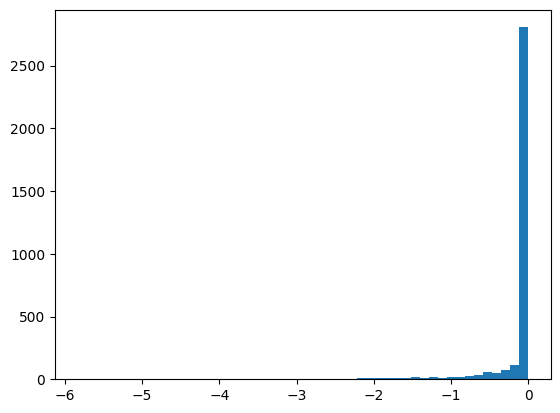

In [27]:
plt.hist(np.log10(df_distinct[df_distinct["layer"]==0].token_specificity), bins=50)

(array([2.000e+00, 4.000e+00, 0.000e+00, 3.000e+00, 1.000e+00, 1.000e+00,
        5.000e+00, 4.000e+00, 5.000e+00, 1.000e+01, 1.200e+01, 8.000e+00,
        1.100e+01, 1.200e+01, 1.800e+01, 2.800e+01, 2.800e+01, 7.900e+01,
        1.190e+02, 7.700e+01, 1.420e+02, 2.480e+02, 3.200e+02, 3.610e+02,
        3.940e+02, 5.400e+02, 7.140e+02, 9.720e+02, 1.274e+03, 1.617e+03,
        1.717e+03, 1.609e+03, 1.548e+03, 1.510e+03, 1.389e+03, 1.377e+03,
        1.338e+03, 1.234e+03, 1.283e+03, 1.147e+03, 1.029e+03, 9.330e+02,
        6.380e+02, 3.870e+02, 1.950e+02, 9.600e+01, 2.700e+01, 1.900e+01,
        6.000e+00, 2.000e+00]),
 array([0.12571087, 0.14450896, 0.16330703, 0.18210511, 0.20090318,
        0.21970126, 0.23849934, 0.2572974 , 0.27609551, 0.29489356,
        0.31369165, 0.33248973, 0.35128781, 0.3700859 , 0.38888395,
        0.40768203, 0.42648011, 0.4452782 , 0.46407628, 0.48287433,
        0.50167239, 0.5204705 , 0.53926861, 0.55806667, 0.57686472,
        0.59566283, 0.61446089, 0.63

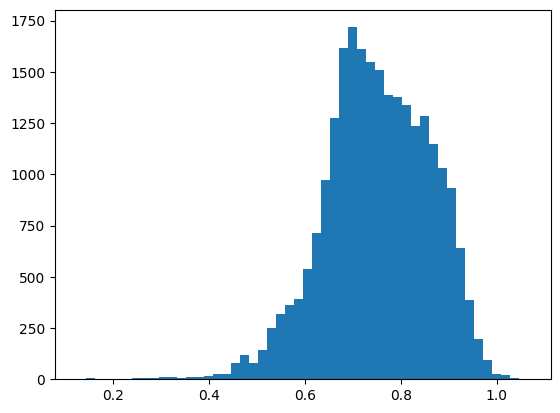

In [36]:
plt.hist(np.log10(df_distinct.metrics_L2), bins=50)

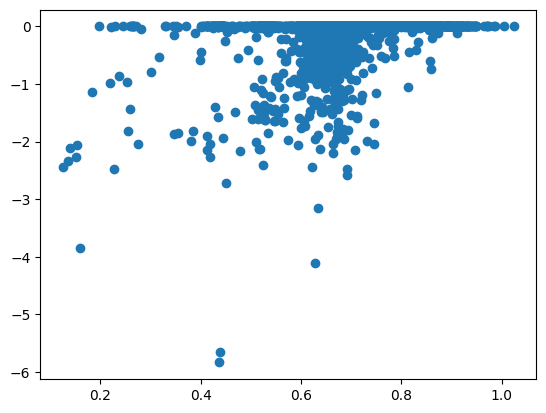

In [33]:
plt.scatter(np.log10(df_distinct[df_distinct["layer"]==0].inverse_layer_mass), np.log10(df_distinct[df_distinct["layer"]==0].token_specificity))

(array([1.1000000e+01, 2.0800000e+02, 6.3230000e+03, 1.1841700e+05,
        9.3342000e+05, 7.9981320e+06, 5.0153262e+07, 2.8473370e+07,
        1.8076150e+06, 6.3900000e+03]),
 array([-13.18686581, -11.86817932, -10.54949284,  -9.23080635,
         -7.91211939,  -6.5934329 ,  -5.27474594,  -3.95605946,
         -2.63737297,  -1.31868649,   0.        ]),
 <BarContainer object of 10 artists>)

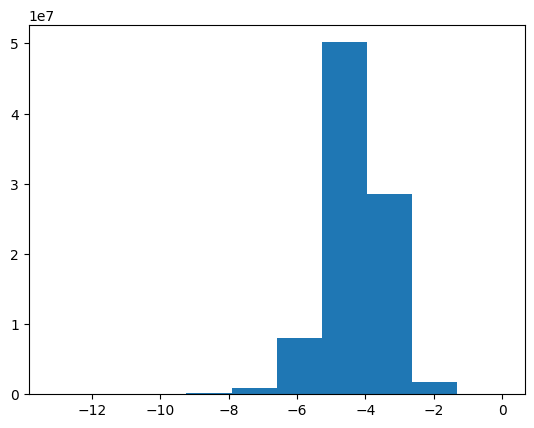

In [10]:
plt.hist(np.log10(full_df.activation_score))

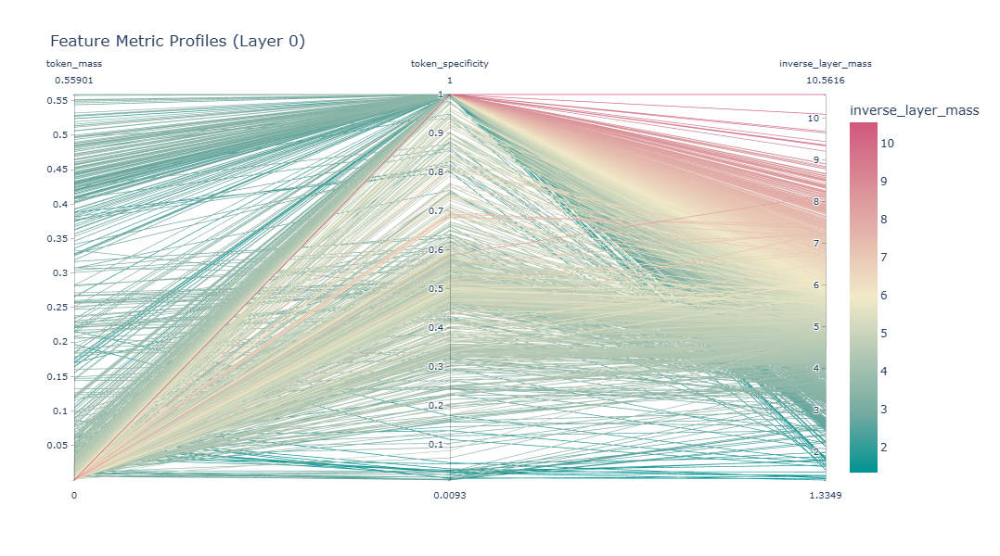

In [43]:
plot_parallel_feature_profiles(full_df, 0)

In [ ]:
# create_sequential_cofiring_sankey(full_df, top_k_links=200, save_path="../figures/mib-bench_ioi_full/co-activations_snakey.html")

Number of unique features: 24493


KeyboardInterrupt: 

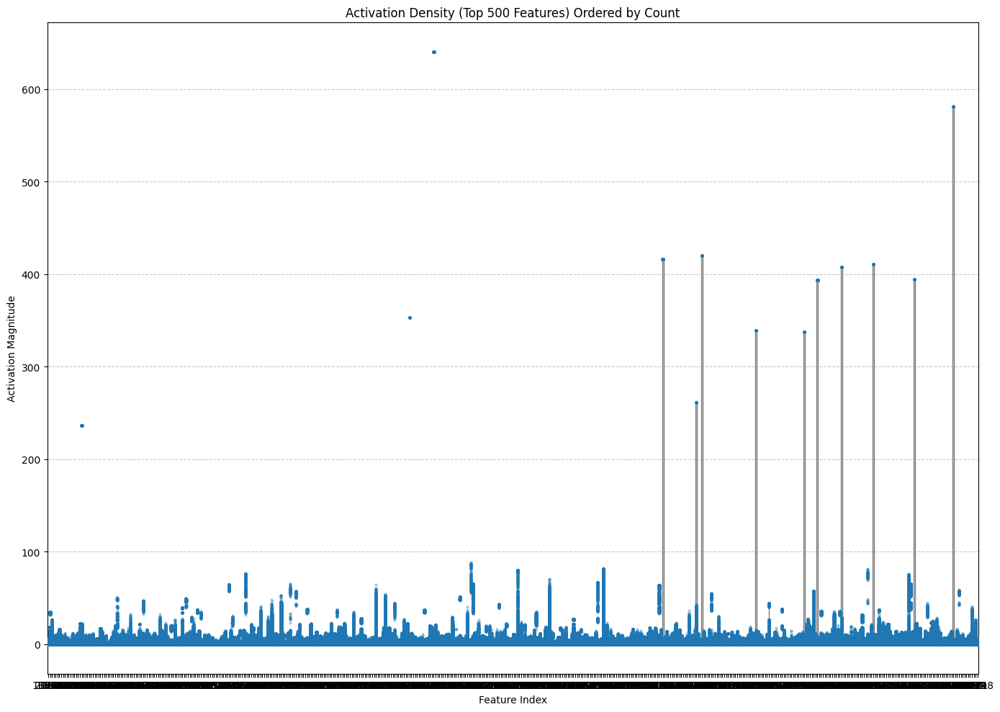

In [11]:
analyze_layer(full_df, top_k=500, save_dir="../figures/mib-bench_ioi_full/")

In [18]:
for layer_id in tqdm(range(12)):
    dataset = ds.dataset(f"../sae_activations/layer={layer_id}", format='parquet')
    layer_df = dataset.to_table().to_pandas()
    analyze_layer(layer_df, top_k=200, save_dir=f"../figures/mib-bench_ioi_full/layer={layer_id}")

  0%|          | 0/12 [00:00<?, ?it/s]

Number of unique features: 3326
Number of unique features: 2811
Number of unique features: 3002
Number of unique features: 4433
Number of unique features: 6076
Number of unique features: 7723
Number of unique features: 8898
Number of unique features: 9658
Number of unique features: 10787
Number of unique features: 11728
Number of unique features: 11144
Number of unique features: 19771


In [22]:
filtered_full_df_0_1 = full_df[full_df["activation"] > 0.1]

In [23]:
create_sequential_cofiring_sankey(filtered_full_df_0_1, top_k_links=200, save_path="../figures/mib-bench_ioi_threshold_0_1/co-activations_snakey.html")

Mapping causal transitions...


  0%|          | 0/11 [00:00<?, ?it/s]

Rendering visualization...


In [24]:
for layer_id in tqdm(range(12)):
    dataset = ds.dataset(f"../sae_activations/layer={layer_id}", format='parquet')
    layer_df = dataset.to_table().to_pandas()
    filtered_layer_df_0_1 = layer_df[layer_df["activation"] > 0.1]
    analyze_layer(filtered_layer_df_0_1, top_k=200, save_dir=f"../figures/mib-bench_ioi_threshold_0_1/layer={layer_id}")

  0%|          | 0/12 [00:00<?, ?it/s]

Number of unique features: 1630
Number of unique features: 2435
Number of unique features: 2771
Number of unique features: 4189
Number of unique features: 5783
Number of unique features: 7374
Number of unique features: 8567
Number of unique features: 9344
Number of unique features: 10451
Number of unique features: 11401
Number of unique features: 10895
Number of unique features: 19618


In [25]:
filtered_full_df_1_0 = full_df[full_df["activation"] > 1.0]

In [26]:
create_sequential_cofiring_sankey(filtered_full_df_1_0, top_k_links=200, save_path="../figures/mib-bench_ioi_threshold_1_0/co-activations_snakey.html")

Mapping causal transitions...


  0%|          | 0/11 [00:00<?, ?it/s]

Rendering visualization...


In [ ]:
for layer_id in tqdm(range(12)):
    dataset = ds.dataset(f"../sae_activations/layer={layer_id}", format='parquet')
    layer_df = dataset.to_table().to_pandas()
    filtered_layer_df_1_0 = layer_df[layer_df["activation"] > 1.0]
    analyze_layer(filtered_layer_df_1_0, top_k=200, save_dir=f"../figures/mib-bench_ioi_threshold_1_0/layer={layer_id}")

In [15]:
filtered_full_df_2 = full_df[full_df["activation"] > 2.0]

In [16]:
create_sequential_cofiring_sankey(filtered_full_df_2, top_k_links=200, save_path="../figures/mib-bench_ioi_threshold_2/co-activations_snakey.html")

Mapping causal transitions...


  0%|          | 0/11 [00:00<?, ?it/s]

Rendering visualization...


In [18]:
for layer_id in tqdm(range(12)):
    dataset = ds.dataset(f"../sae_activations/layer={layer_id}", format='parquet')
    layer_df = dataset.to_table().to_pandas()
    filtered_layer_df_2 = layer_df[layer_df["activation"] > 2.0]
    analyze_layer(filtered_layer_df_2, top_k=200, save_dir=f"../figures/mib-bench_ioi_threshold_2/layer={layer_id}")

  0%|          | 0/12 [00:00<?, ?it/s]

Number of unique features: 223
Number of unique features: 1205
Number of unique features: 1300
Number of unique features: 1826
Number of unique features: 2584
Number of unique features: 3340
Number of unique features: 4107
Number of unique features: 4700
Number of unique features: 5402
Number of unique features: 6379
Number of unique features: 7110
Number of unique features: 16186


In [25]:
full_df["percent_rank"] = full_df["activation"].astype("float32").groupby(full_df["layer"]).rank(pct=True)
full_df

/lv_local/home/maximilian.m/anaconda3/envs/sae/lib/python3.11/site-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,prompt_idx,token_idx,token_id,feature_idx,activation,layer,percent_rank
0,6150,0,50256,663,1.609375,0,0.926714
1,6150,0,50256,14525,1.477539,0,0.913276
2,6150,0,50256,15967,1.561523,0,0.918588
3,6150,0,50256,16436,1.629883,0,0.930608
4,6150,0,50256,19038,1.564453,0,0.922331
...,...,...,...,...,...,...,...
89497143,869,19,284,23655,0.576660,9,0.292953
89497144,869,19,284,24120,14.375000,9,0.968977
89497145,869,19,284,24198,0.957520,9,0.422204
89497146,869,19,284,24284,1.144531,9,0.473762


In [26]:
filtered_full_df_d1 = full_df[full_df["percent_rank"] >= 0.9]

In [27]:
create_sequential_cofiring_sankey(filtered_full_df_d1, top_k_links=200, save_path="../figures/mib-bench_ioi_d1/co-activations_snakey.html")

Mapping causal transitions...


  0%|          | 0/11 [00:00<?, ?it/s]

Rendering visualization...


In [29]:
for layer_id in tqdm(range(12)):
    layer_df = filtered_full_df_d1[filtered_full_df_d1["layer"] == layer_id]
    analyze_layer(layer_df, top_k=200, save_dir=f"../figures/mib-bench_ioi_d1/layer={layer_id}")

  0%|          | 0/12 [00:00<?, ?it/s]

Number of unique features: 262
Number of unique features: 311
Number of unique features: 393
Number of unique features: 623
Number of unique features: 954
Number of unique features: 1246
Number of unique features: 1438
Number of unique features: 1853
Number of unique features: 1944
Number of unique features: 2096
Number of unique features: 1874
Number of unique features: 4358


In [33]:
filtered_full_df_d80 = full_df[full_df["percent_rank"] >= 0.8]

In [34]:
create_sequential_cofiring_sankey(filtered_full_df_d80, top_k_links=200, save_path="../figures/mib-bench_ioi_d80/co-activations_snakey.html")

Mapping causal transitions...


  0%|          | 0/11 [00:00<?, ?it/s]

Rendering visualization...


In [35]:
for layer_id in tqdm(range(12)):
    layer_df = filtered_full_df_d80[filtered_full_df_d80["layer"] == layer_id]
    analyze_layer(layer_df, top_k=200, save_dir=f"../figures/mib-bench_ioi_d80/layer={layer_id}")

  0%|          | 0/12 [00:00<?, ?it/s]

Number of unique features: 348
Number of unique features: 629
Number of unique features: 934
Number of unique features: 1313
Number of unique features: 1850
Number of unique features: 2660
Number of unique features: 2956
Number of unique features: 3362
Number of unique features: 3679
Number of unique features: 3993
Number of unique features: 3579
Number of unique features: 8170


In [30]:
filtered_full_df_q4 = full_df[full_df["percent_rank"] >= 0.75]

In [31]:
create_sequential_cofiring_sankey(filtered_full_df_q4, top_k_links=200, save_path="../figures/mib-bench_ioi_q4/co-activations_snakey.html")

Mapping causal transitions...


  0%|          | 0/11 [00:00<?, ?it/s]

Rendering visualization...


In [32]:
for layer_id in tqdm(range(12)):
    layer_df = filtered_full_df_q4[filtered_full_df_q4["layer"] == layer_id]
    analyze_layer(layer_df, top_k=200, save_dir=f"../figures/mib-bench_ioi_q4/layer={layer_id}")

  0%|          | 0/12 [00:00<?, ?it/s]

Number of unique features: 374
Number of unique features: 813
Number of unique features: 1150
Number of unique features: 1614
Number of unique features: 2184
Number of unique features: 3140
Number of unique features: 3665
Number of unique features: 4011
Number of unique features: 4353
Number of unique features: 4829
Number of unique features: 4356
Number of unique features: 9809


In [13]:
import pandas as pd

df = pd.read_parquet("../sae_activations/layer=0/007531aeb57242008d711ba42a5fe206-0.parquet", engine="pyarrow")
df

/lv_local/home/maximilian.m/anaconda3/envs/sae/lib/python3.11/site-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,prompt_idx,token_idx,token_id,feature_idx,activation
0,6150,0,50256,663,1.609375
1,6150,0,50256,14525,1.477539
2,6150,0,50256,15967,1.561523
3,6150,0,50256,16436,1.629883
4,6150,0,50256,19038,1.564453
...,...,...,...,...,...
2688,6159,15,284,16627,0.158569
2689,6159,15,284,18458,0.318848
2690,6159,15,284,19064,0.296387
2691,6159,15,284,20530,0.038879


Number of unique features: 555


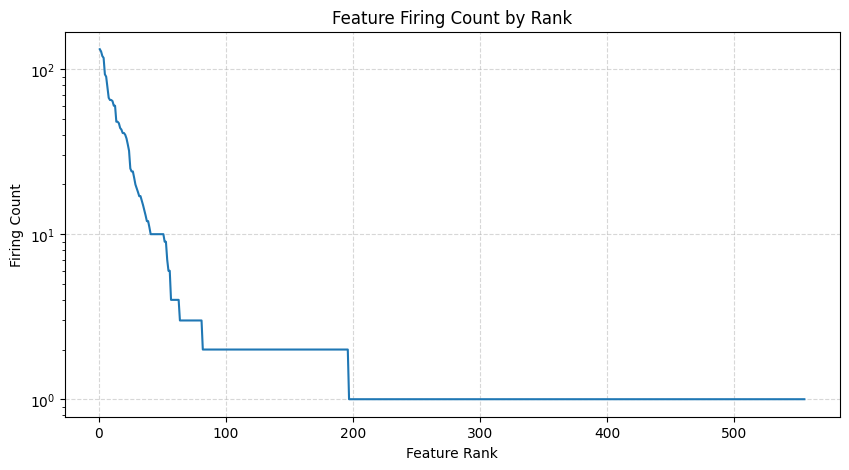

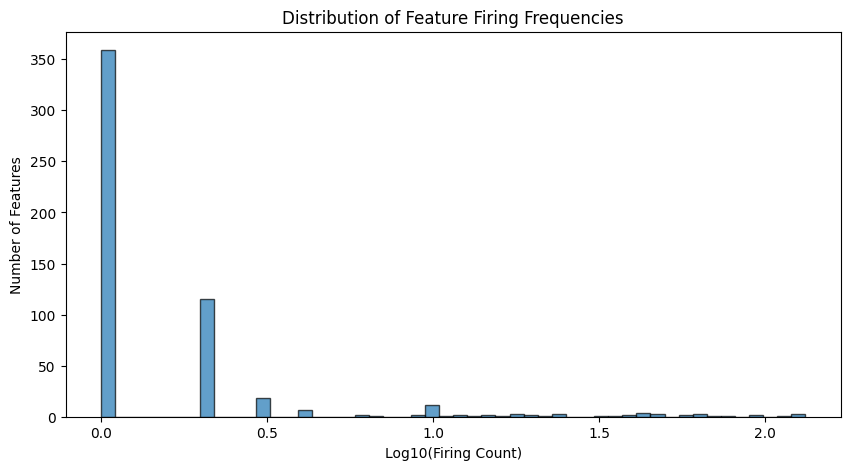

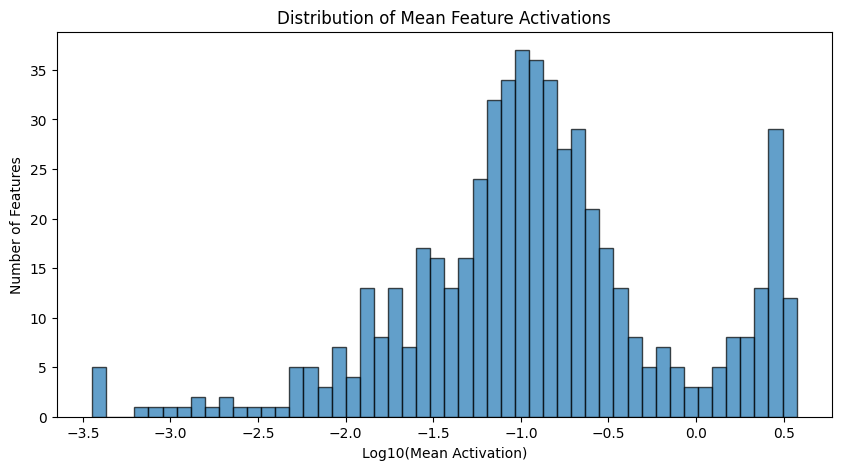

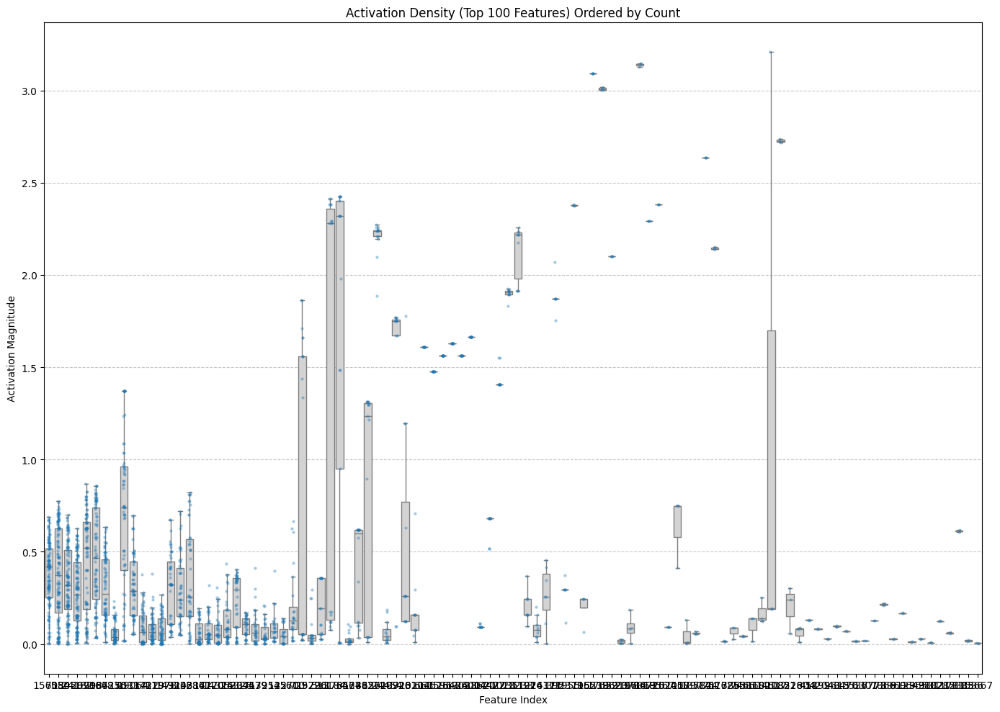

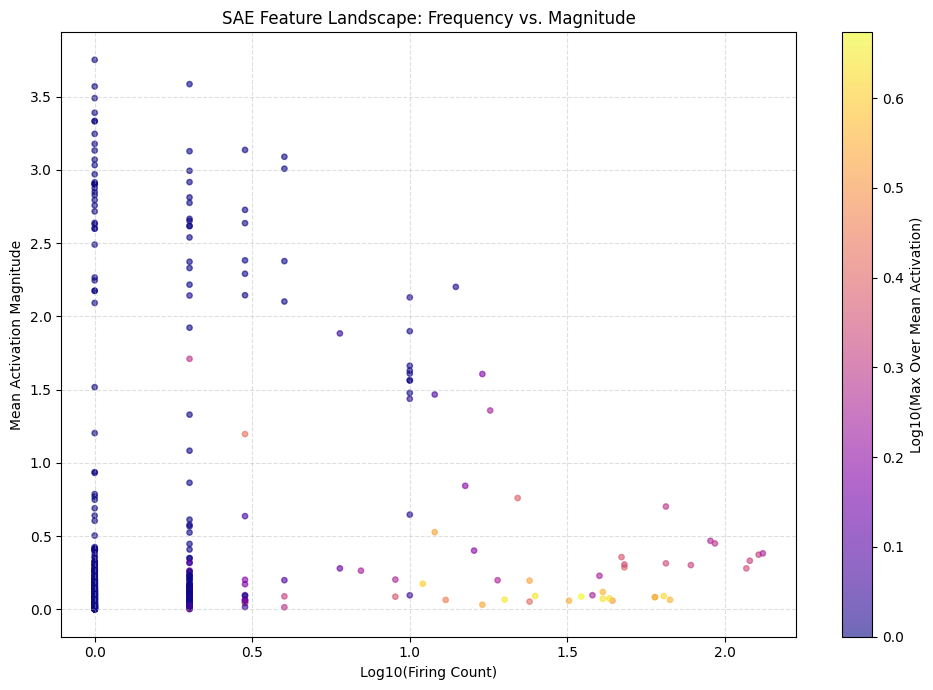

...

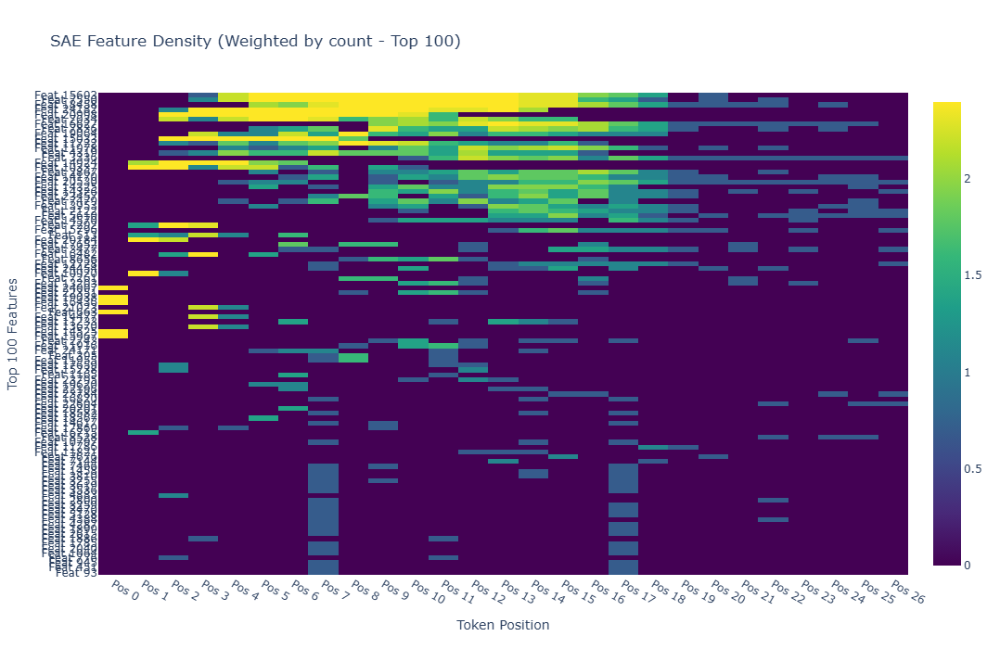

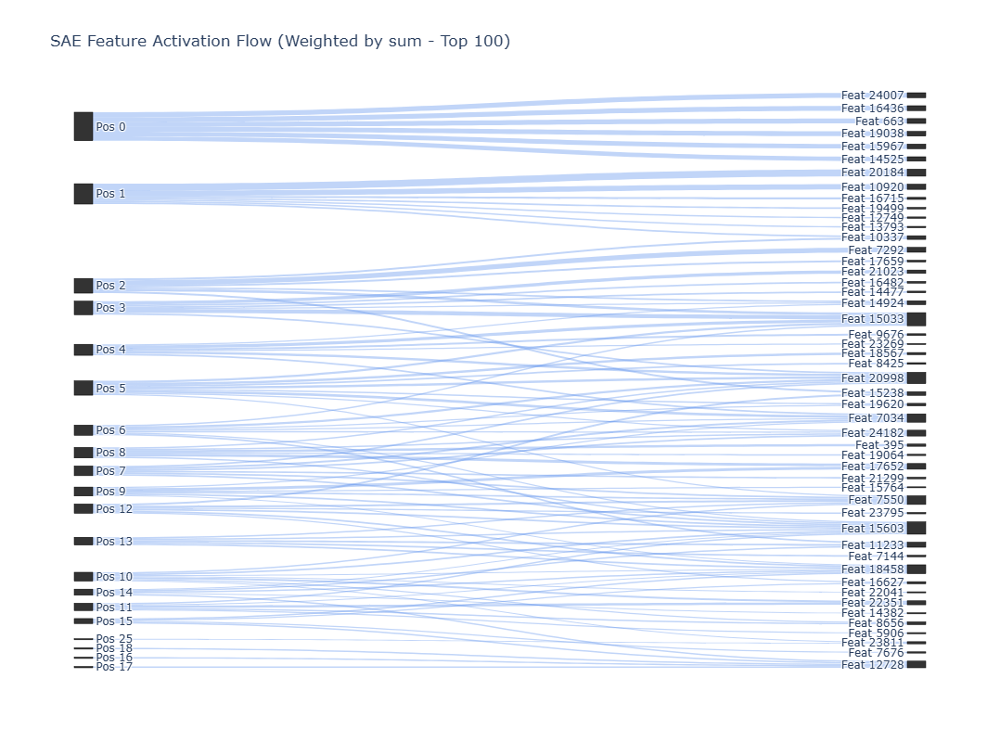

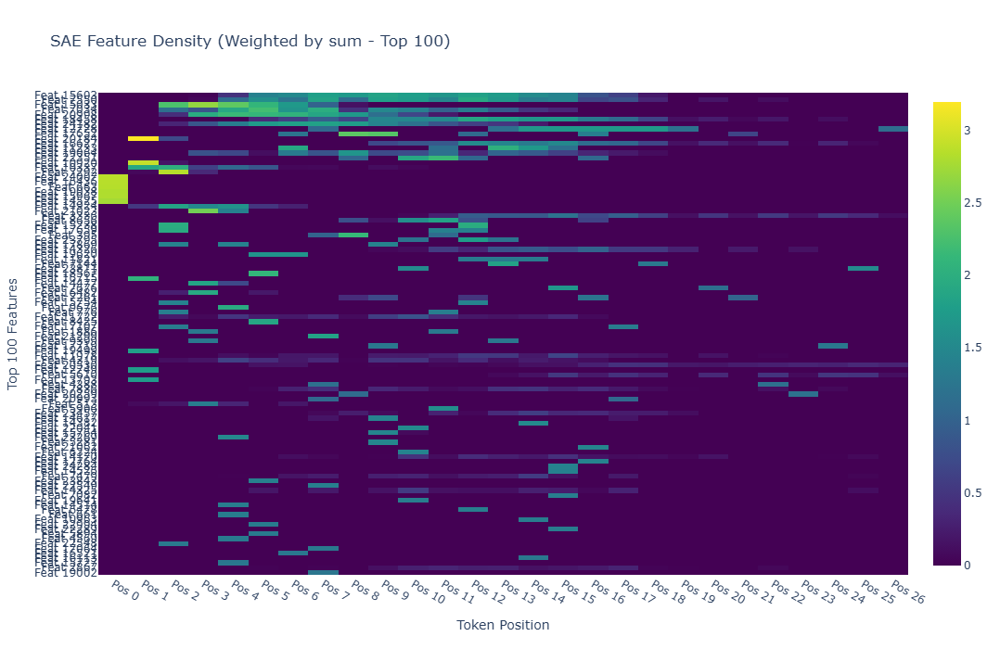

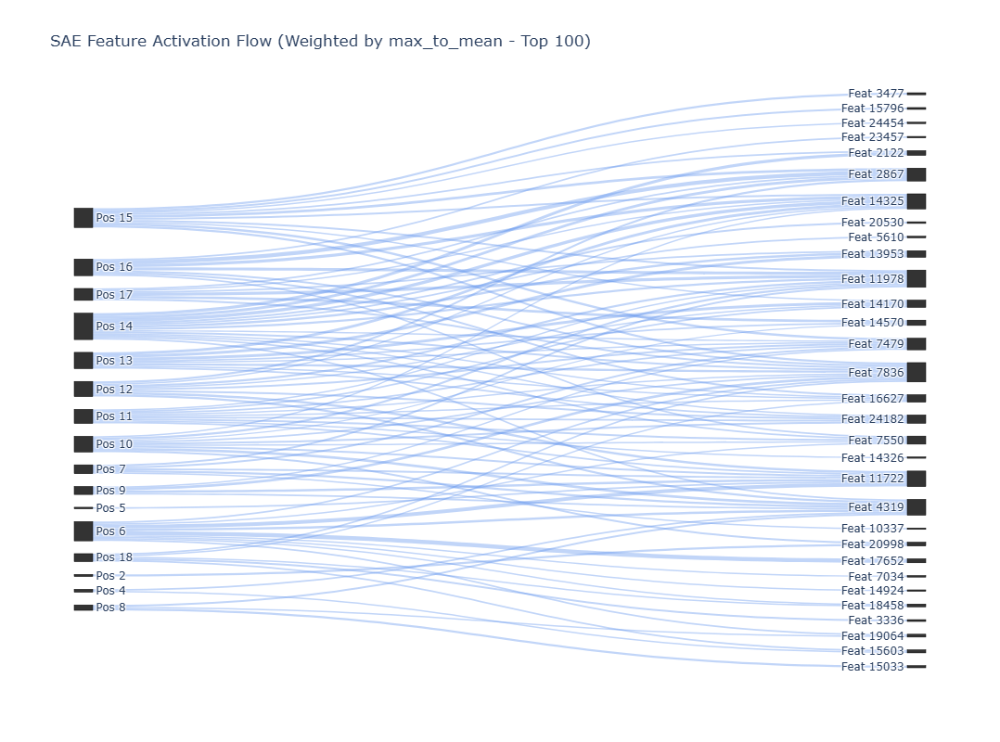

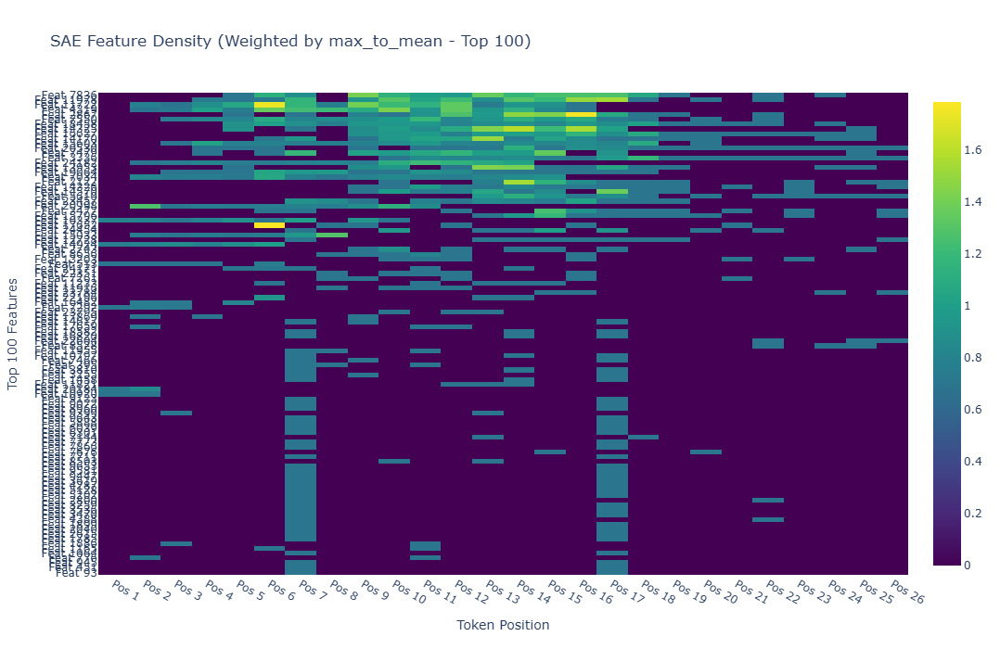

In [14]:
analyze_layer(df)

Number of unique features: 24493


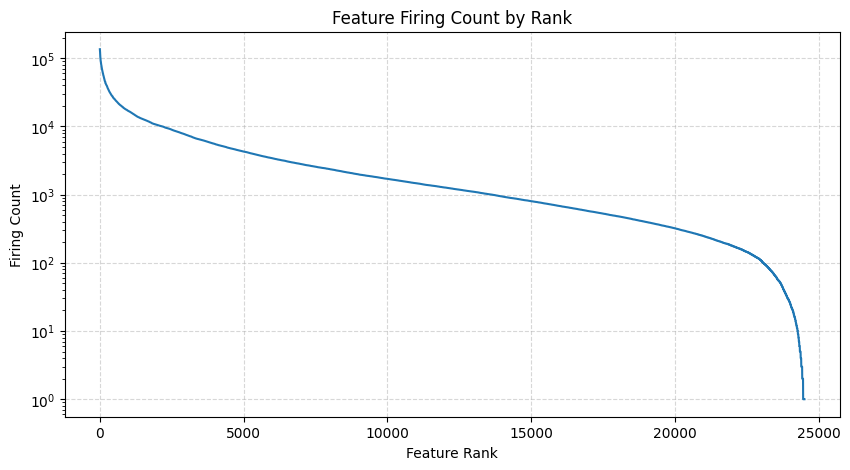

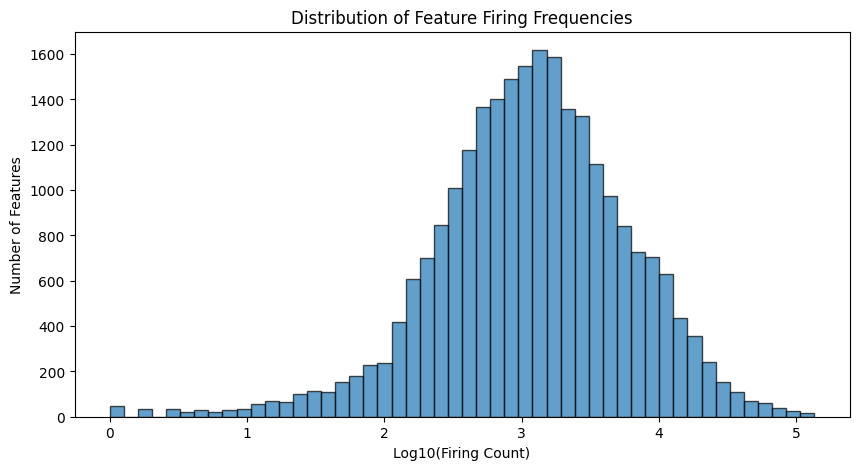

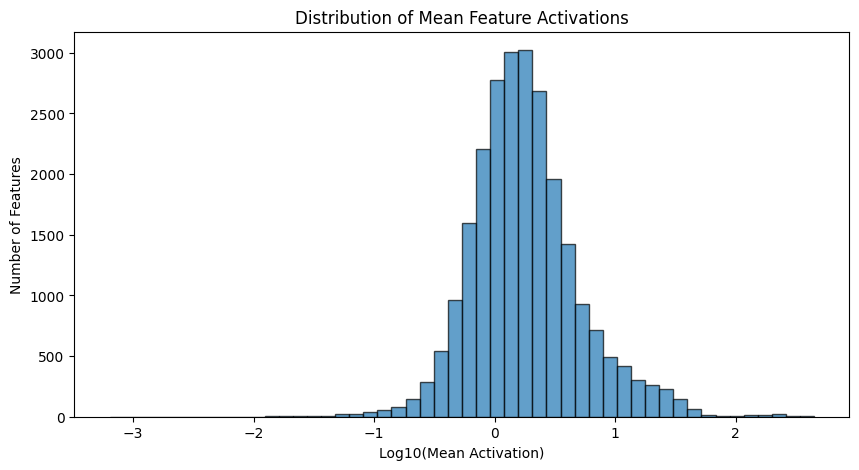

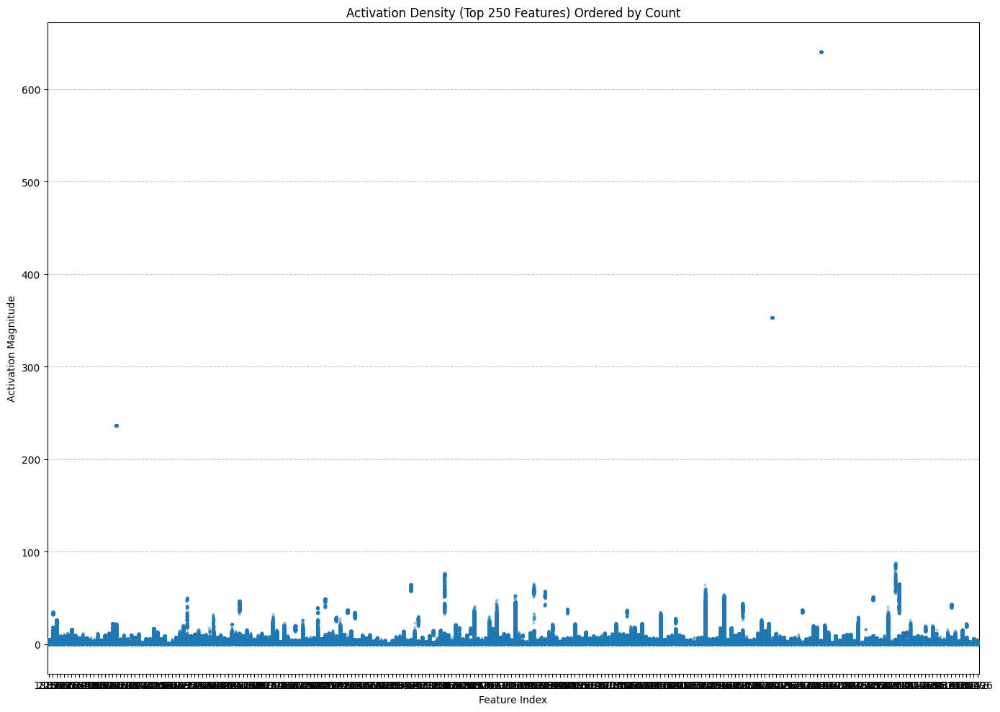

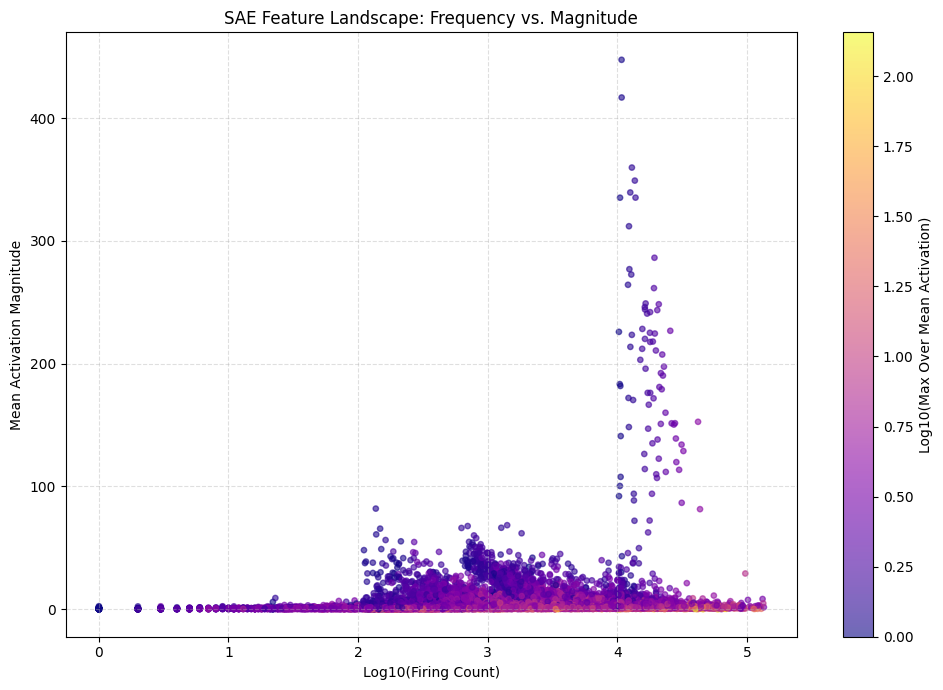

...

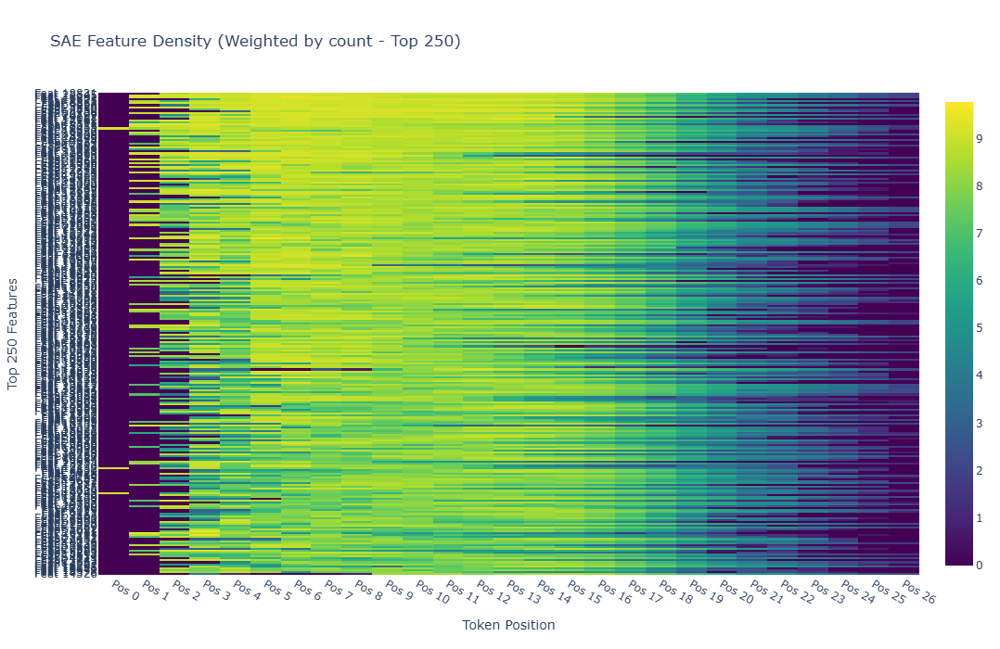

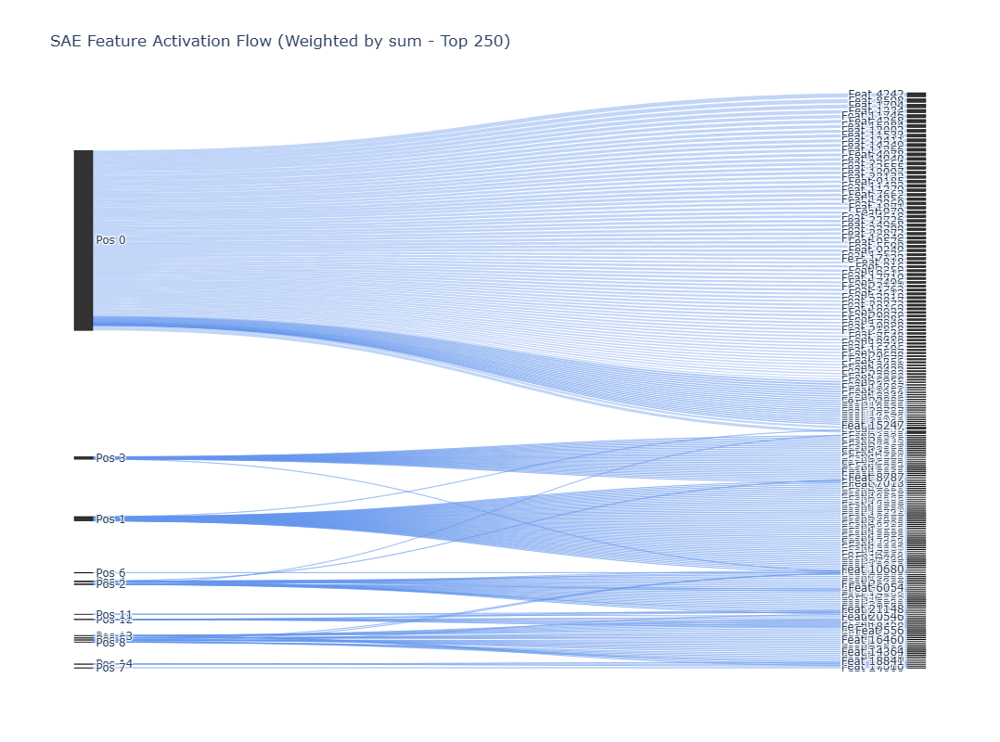

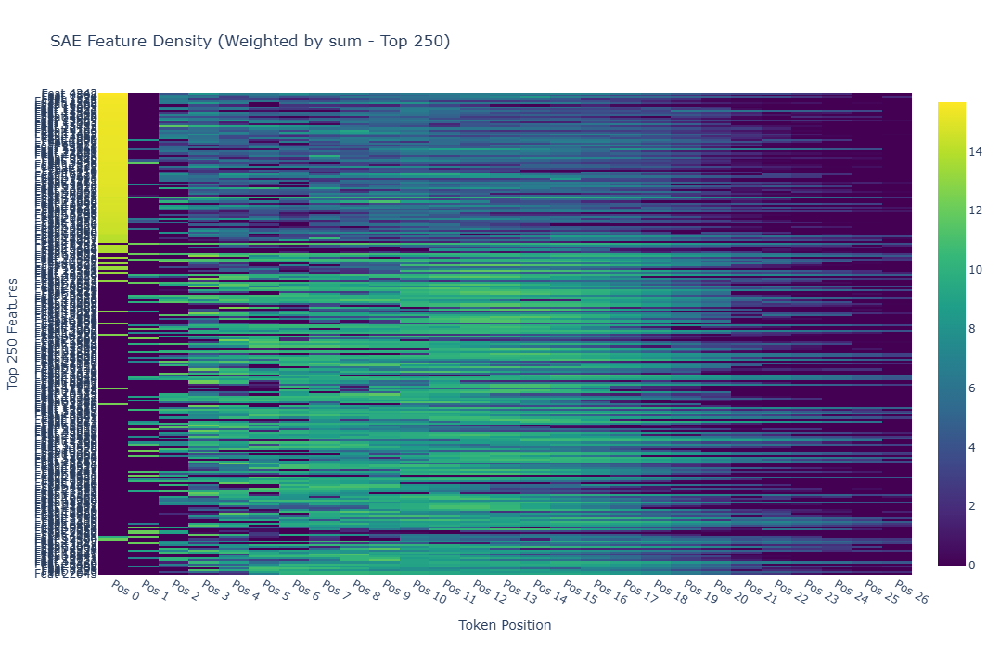

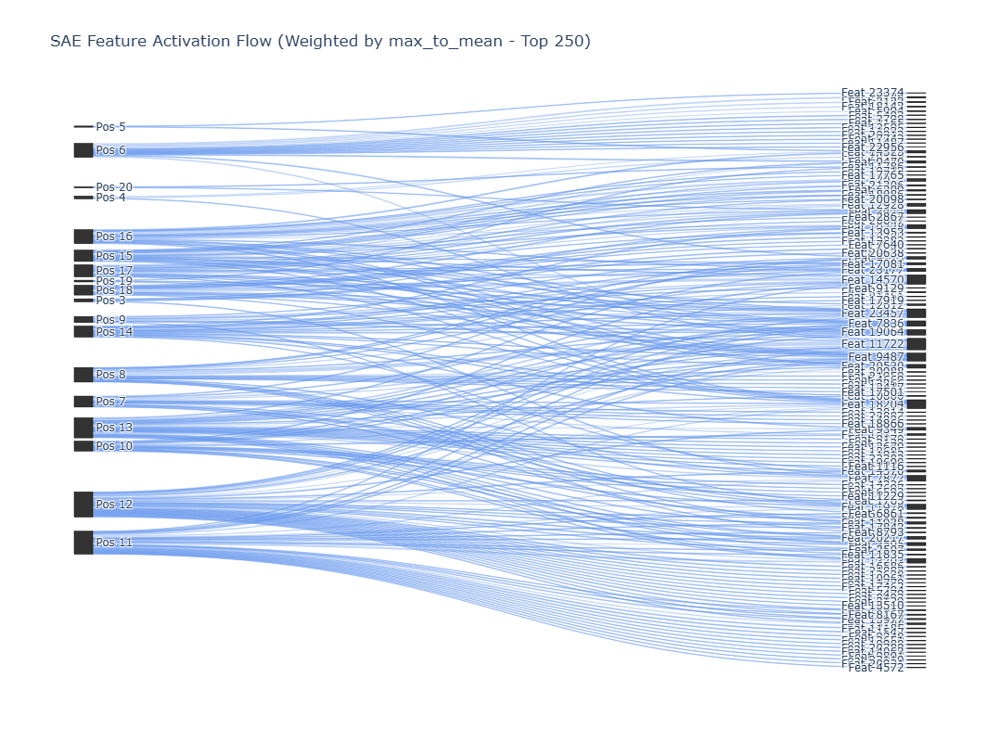

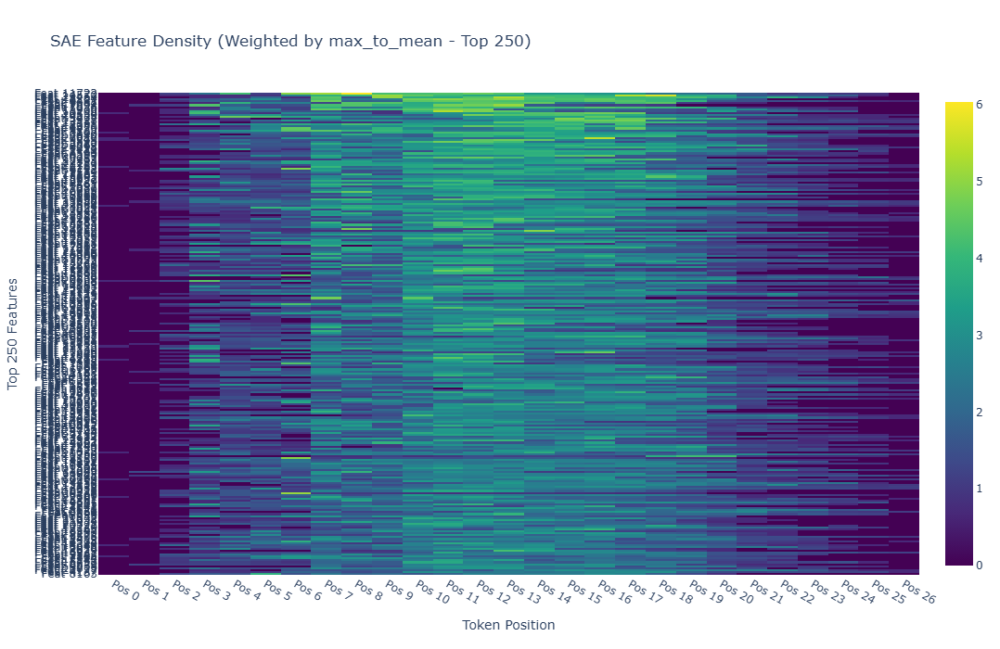

In [22]:
analyze_layer(full_df,top_k=250)

In [15]:
df["token_idx"].nunique()

27

In [10]:
import matplotlib.pyplot as plt

counts = df['feature_idx'].value_counts()

In [12]:
counts

feature_idx
15603    132
7550     128
18458    120
24182    117
20998     93
        ... 
10963      1
14526      1
5281       1
14909      1
14382      1
Name: count, Length: 555, dtype: int64

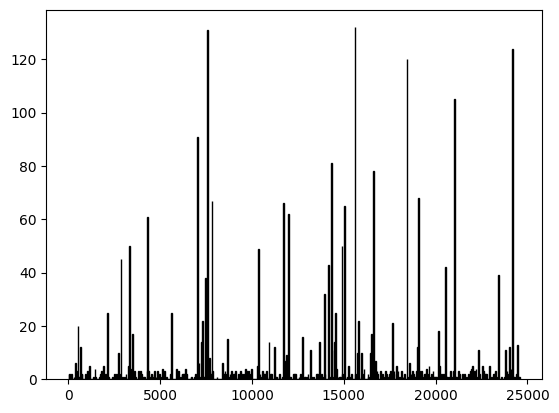

In [11]:
plt.hist(counts.index, bins=len(counts), weights=counts.values, edgecolor="black")
plt.show()

(array([359., 115.,  25.,   3.,  14.,   9.,   6.,  11.,   7.,   6.]),
 array([0.        , 0.21205739, 0.42411479, 0.63617218, 0.84822957,
        1.06028697, 1.27234436, 1.48440175, 1.69645914, 1.90851654,
        2.12057393]),
 <BarContainer object of 10 artists>)

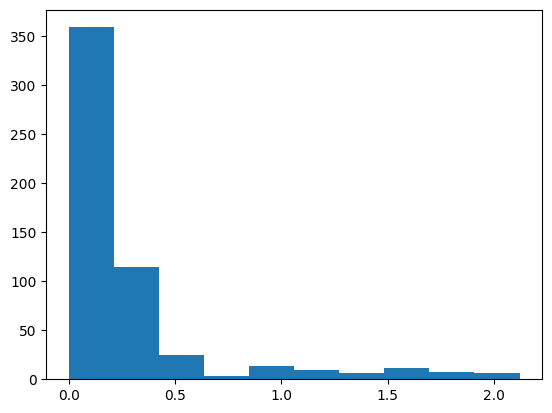

In [16]:
import numpy as np

plt.hist(counts.apply(np.log10))

In [18]:
avg_feature_activation = df.groupby("feature_idx")[["activation"]].mean()
avg_feature_activation

,activation
feature_idx,
25,0.158691
65,0.033508
93,0.049942
160,0.231567
199,0.041840
...,...
24284,3.132812
24401,0.320251
24454,0.063852


(array([  7.,   7.,   9.,  32.,  61., 119., 163.,  64.,  23.,  70.]),
 array([-3.44714808, -3.04500747, -2.64286709, -2.24072647, -1.83858585,
        -1.43644524, -1.03430486, -0.63216424, -0.23002362,  0.17211699,
         0.57425743]),
 <BarContainer object of 10 artists>)

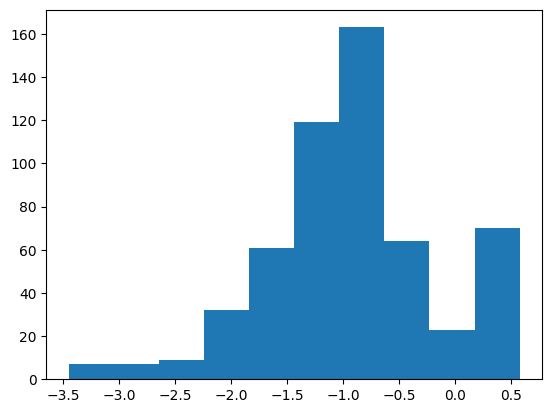

In [27]:
plt.hist(avg_feature_activation["activation"].apply(np.log10))

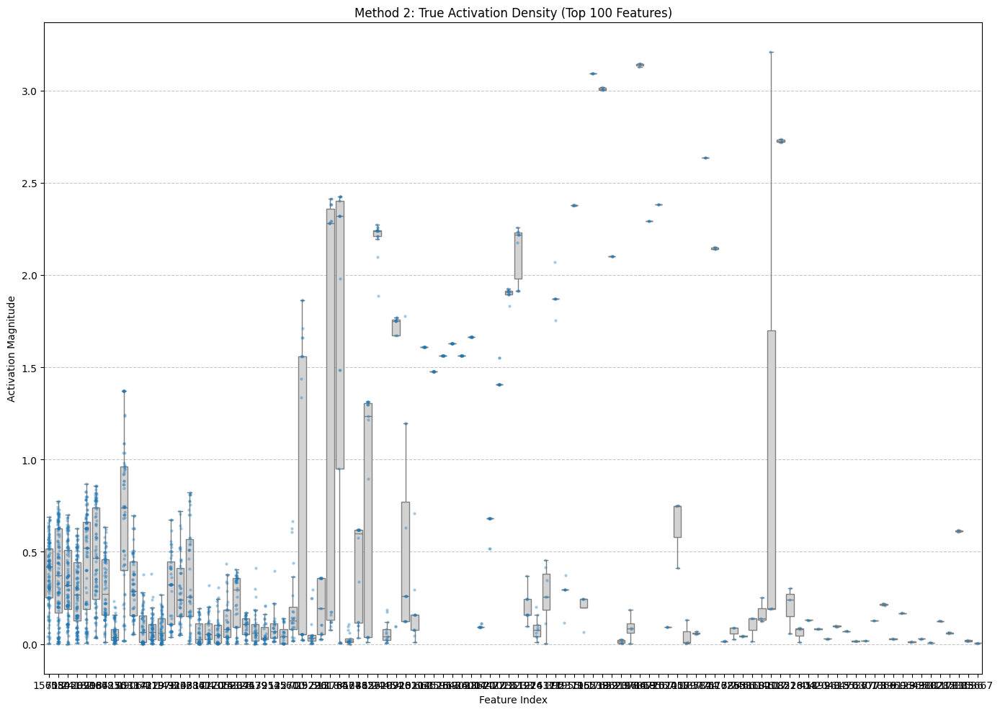

In [40]:
import pandas as pd
import seaborn as sns

top_n = 100
top_features = df['feature_idx'].value_counts().nlargest(top_n).index
df_top = df[df['feature_idx'].isin(top_features)]

# Create the figure and axis
fig, ax = plt.subplots(figsize=(14, 10))

# Boxplot
sns.boxplot(
    data=df_top, 
    x='feature_idx', 
    y='activation', 
    order=top_features, 
    color='lightgray',
    showfliers=False,
    ax=ax
)

# Stripplot
sns.stripplot(
    data=df_top, 
    x='feature_idx', 
    y='activation', 
    order=top_features, 
    alpha=0.4, 
    size=3,
    jitter=True,
    ax=ax
)

# Formatting
ax.set_title(f"Method 2: True Activation Density (Top {top_n} Features)")
ax.set_xlabel("Feature Index")
ax.set_ylabel("Activation Magnitude")
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

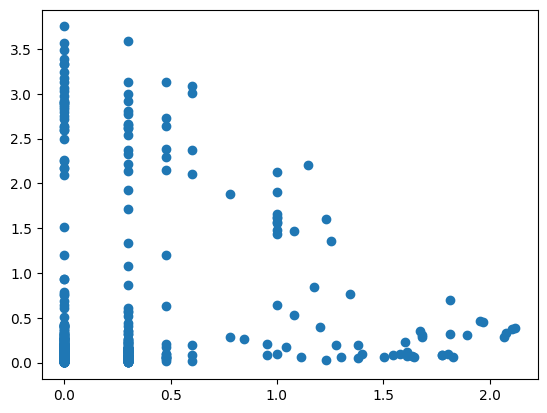

In [55]:
feat_stats = flat_df.groupby('feature_idx')['activation'].agg(['max', 'mean', 'count']).reset_index()
plt.scatter(feat_stats["count"].apply(np.log10), feat_stats["mean"])

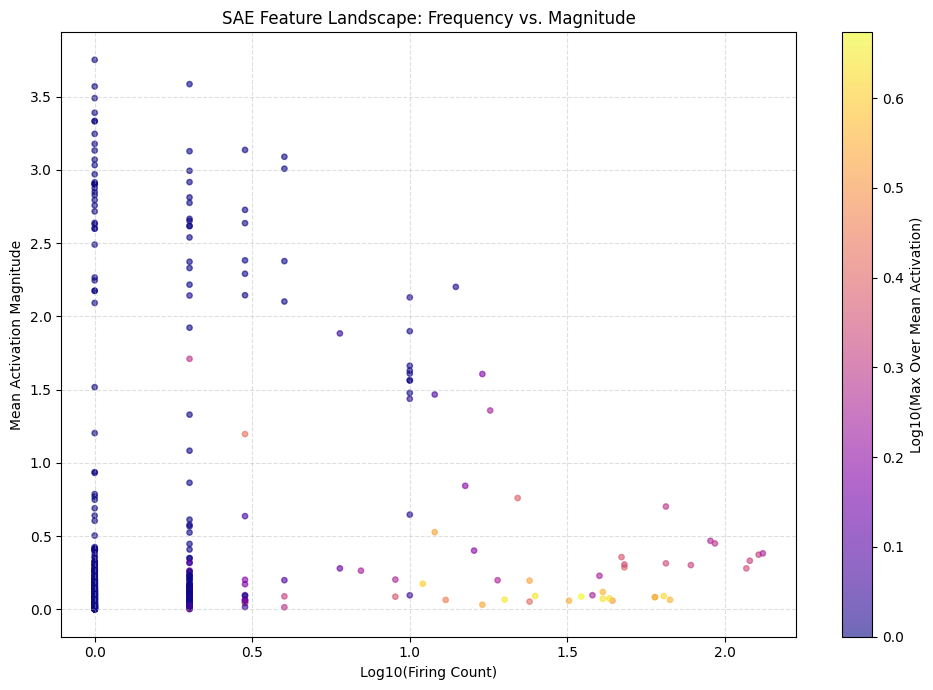

In [56]:
flat_df = df[['feature_idx', 'activation']]

feat_stats = df.groupby('feature_idx')['activation'].agg(['max', 'mean', 'count']).reset_index()

total_activations = len(flat_df)
feat_stats['max_to_mean_ratio'] = feat_stats['max'] / feat_stats['mean']

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    np.log10(feat_stats['count']), 
    feat_stats['mean'], 
    c=np.log10(feat_stats['max_to_mean_ratio']),
    cmap='plasma', 
    alpha=0.6, 
    s=15
)

ax.set_title("SAE Feature Landscape: Frequency vs. Magnitude")
ax.set_xlabel("Log10(Firing Count)")
ax.set_ylabel("Mean Activation Magnitude")

cb = fig.colorbar(sc, ax=ax)
cb.set_label("Log10(Max Over Mean Activation)")

ax.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [49]:
flat_df

/lv_local/home/maximilian.m/anaconda3/envs/sae/lib/python3.11/site-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,feature_idx,activation
0,663,1.609375
1,14525,1.477539
2,15967,1.561523
3,16436,1.629883
4,19038,1.564453
...,...,...
2688,16627,0.158569
2689,18458,0.318848
2690,19064,0.296387
2691,20530,0.038879


Aggregating weights...


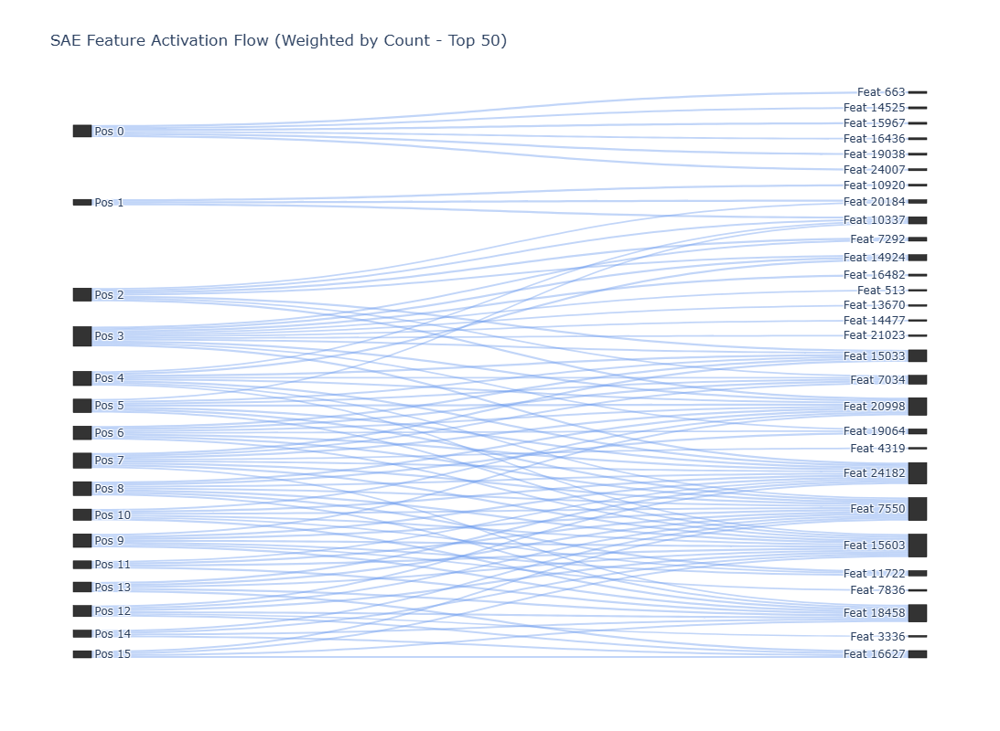

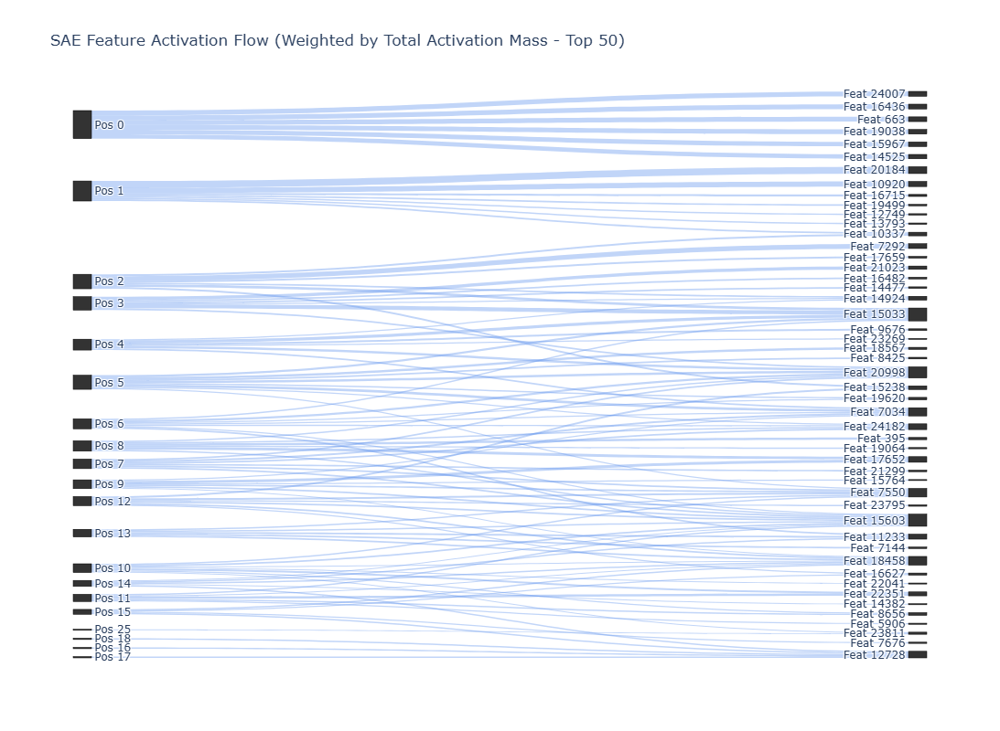

In [6]:
import plotly.graph_objects as go

# 3. Calculate both Count and Sum for every position -> feature path
print("Aggregating weights...")
agg_df = df.groupby(['token_idx', 'feature_idx'])['activation'].agg(['count', 'sum']).reset_index()

def create_interactive_sankey(data, weight_column, title, filename, top_n_links=100):
    """Generates an interactive HTML Sankey diagram for the top N connections."""
    
    # Isolate the heaviest/most frequent paths to prevent rendering a hairball
    top_paths = data.nlargest(top_n_links, weight_column).reset_index(drop=True)
    
    # Create unique string names for the nodes to prevent ID collisions
    token_nodes = [f"Pos {pos}" for pos in top_paths['token_idx'].unique()]
    feature_nodes = [f"Feat {f_idx}" for f_idx in top_paths['feature_idx'].unique()]
    all_nodes = token_nodes + feature_nodes
    
    node_map = {name: i for i, name in enumerate(all_nodes)}
    
    # Map the Dataframe columns to Plotly's Source -> Target integer indices
    sources = top_paths['token_idx'].apply(lambda x: node_map[f"Pos {x}"]).tolist()
    targets = top_paths['feature_idx'].apply(lambda x: node_map[f"Feat {x}"]).tolist()
    values = top_paths[weight_column].tolist()
    
    fig = go.Figure(data=[go.Sankey(
        node = dict(
          pad = 15,
          thickness = 20,
          line = dict(color = "black", width = 0.5),
          label = all_nodes,
          color = "#333333"
        ),
        link = dict(
          source = sources,
          target = targets,
          value = values,
          color = "rgba(100, 149, 237, 0.4)", # Cornflower blue with transparency
          hovertemplate='Source: %{source.label}<br>Target: %{target.label}<br>Weight: %{value}<extra></extra>'
        )
    )])
    
    fig.update_layout(title_text=title, font_size=12, height=800)
    fig.show()

# Generate Variation 1
create_interactive_sankey(
    agg_df, 
    weight_column='count', 
    title=f"SAE Feature Activation Flow (Weighted by Count - Top 50)", 
    filename="sankey_by_count.html"
)

# Generate Variation 2
create_interactive_sankey(
    agg_df, 
    weight_column='sum', 
    title=f"SAE Feature Activation Flow (Weighted by Total Activation Mass - Top 50)", 
    filename="sankey_by_sum.html"
)

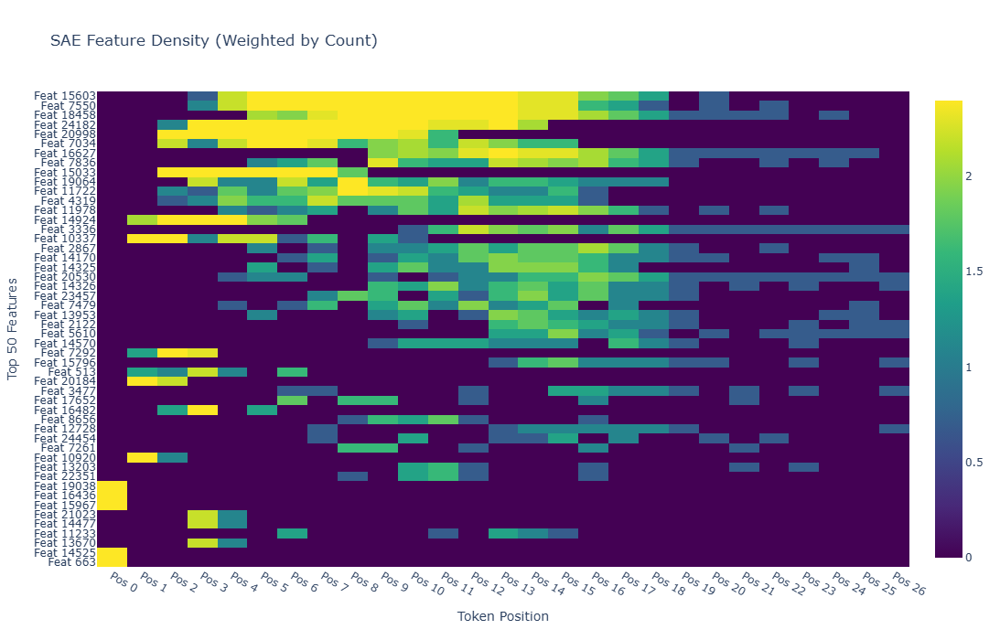

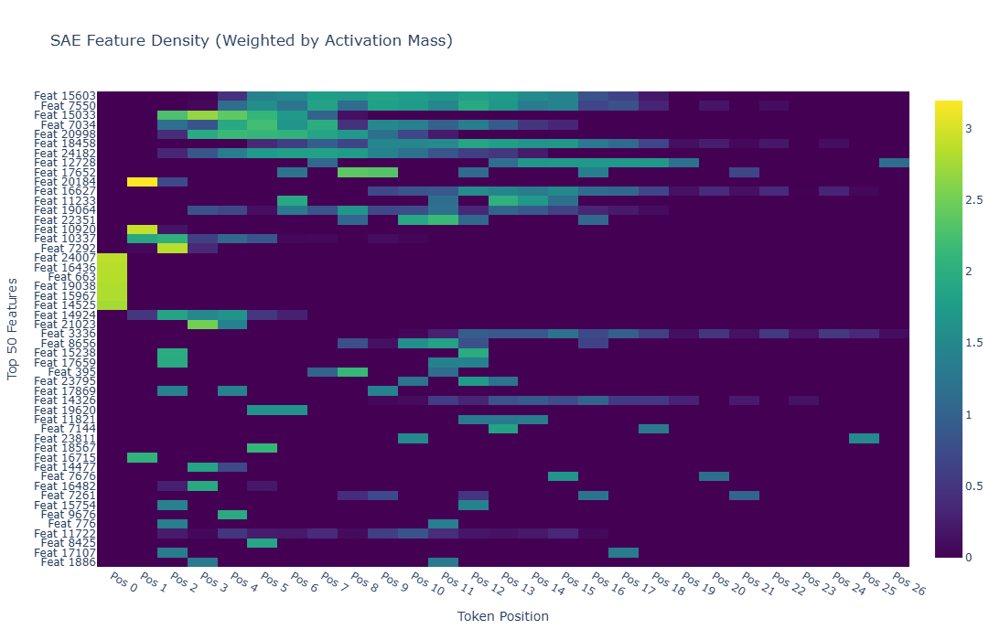

In [11]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# Assuming `agg_df` is still in memory from the previous execution.
# If not, recreate it:
# flat_df = df[['token_idx', 'feature_indices', 'activations']].explode(['feature_indices', 'activations'])
# flat_df[['activations', 'feature_indices']] = flat_df[['activations', 'feature_indices']].astype(float)
# agg_df = flat_df.groupby(['token_idx', 'feature_indices'])['activations'].agg(['count', 'sum']).reset_index()

def create_inline_heatmap(data, weight_column, title, top_n_features=50):
    top_features = data.groupby('feature_idx')[weight_column].sum().nlargest(top_n_features).index
    filtered_data = data[data['feature_idx'].isin(top_features)]
    
    matrix = filtered_data.pivot(index='feature_idx', columns='token_idx', values=weight_column).fillna(0)
    
    matrix['total_weight'] = matrix.sum(axis=1)
    matrix = matrix.sort_values('total_weight', ascending=True).drop(columns=['total_weight'])
    
    z_raw = matrix.values
    z_log = np.log1p(z_raw)
    
    y_labels = [f"Feat {int(f)}" for f in matrix.index]
    x_labels = [f"Pos {int(p)}" for p in matrix.columns]
    
    fig = go.Figure(data=go.Heatmap(
        z=z_log, 
        x=x_labels,
        y=y_labels,
        customdata=z_raw, 
        colorscale='Viridis',
        hovertemplate='Position: %{x}<br>Feature: %{y}<br>Raw Value: %{customdata:,.2f}<extra></extra>'
    ))
    
    fig.update_layout(
        title_text=title,
        xaxis_title="Token Position",
        yaxis_title=f"Top {top_n_features} Features",
        height=700,
        yaxis=dict(type='category', dtick=1) 
    )
    
    fig.show()

# Variant 1: Frequency
create_inline_heatmap(agg_df, weight_column='count', title="SAE Feature Density (Weighted by Count)")

# Variant 2: Activation Mass
create_inline_heatmap(agg_df, weight_column='sum', title="SAE Feature Density (Weighted by Activation Mass)")